---
---
# $$ DeBERTa \ for \ math \ misconceptions: \ progressive \ unfreezing and \ dual \ learning \ rates$$

This notebook explores an advanced fine-tuning strategy for **DeBERTa-v3-large** on the *MAP-Charting Student Math Misconceptions* challenge.  
The approach combines three complementary techniques designed to balance stability, adaptability, and fairness across classes:

1. **Progressive Unfreezing** — The training proceeds in multiple phases, during which the encoder layers are incrementally unfrozen.  
   This approach preserves the broad linguistic knowledge in earlier layers, enabling deeper layers to specialize in domain-relevant distinctions.

2. **Dual Learning Rates** — Separate learning rates are applied to the **classifier head** and **unfrozen transformer layers**, ensuring controlled adaptation.  
   The head learns quickly, while deeper layers are fine-tuned more conservatively.

3. **Weighted Loss Optimization** — Custom class weights mitigate the imbalance in misconception frequencies, preventing the model from overfitting to common patterns while still recognizing rare misconceptions.

Together, these elements form a **curriculum-style fine-tuning process** — first stabilizing, then refining, then rebalancing — leading to a more robust and generalizable understanding of student misconceptions.

---
---

# $$Initial \ setup$$

In [1]:
# ==================== CONFIGURATIONS ====================
import torch
class CFG:
    
    DATA_PATH             = "/kaggle/input/map-charting-student-math-misunderstandings/"
    BASE_DIRECTORY        = "models_for_competitions"
    CHALLENGE_NAME        = "MAP-Charting-Student-Math-Misunderstandings"
    MODEL_NAME            = "deberta-v3-large"
    CHECKPOINT            = "/kaggle/input/huggingfacedebertav3variants/deberta-v3-large"
    PRETRAINED_CHECKPOINT = "/kaggle/input/models-for-competitions/.models_for_competitions/MAP-Charting-Student-Math-Misunderstandings/deberta-v3-large_stage2/checkpoint-2295"
    
    TRAINING       = False # True: train models
    PUSH_TO_HUB    = False # True: push models to hub
    PRE_TRAINED    = True  # True: loead and use pre-trained model
    SEED           = 42    # Reproducibility
    VALID_SIZE     = 0.2
    EPOCHS         = 8
    PATIENCE       = 2
    DEVICE         = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
    
    COLOR_1        = 'cornflowerblue'
    COLOR_2        = 'salmon'
    PALETTE        = 'viridis'

In [2]:
# ==================== IMPORT BASE LIBRARIES AND SET RANDOM SEED ====================
import os
import torch
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set Seed for Reproducibility
random.seed(CFG.SEED)
np.random.seed(CFG.SEED)
torch.manual_seed(CFG.SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(CFG.SEED)
# torch.use_deterministic_algorithms(False)

# Set seaborn style
sns.set_style('darkgrid')

In [3]:
# ==================== HELPER FUNCTIONS ====================

def print_with_sep(text,sep="=",n=30):
  print("\n")
  print(sep*n)
  print('\t',text)
  print(sep*n)

# ============================================================
def print_dataset_overview(datasets):

    # Check shapes
    print_with_sep("Shapes")
    for name, df in datasets.items():
      print(f"{name} shape: {df.shape}")
    
    # Check duplicates
    print_with_sep("Duplicates")
    for name, df in datasets.items():
      print(f"{name} duplicates: {df.duplicated().sum()}")
    
    # Check nans
    print_with_sep("NaNs")
    for name, df in datasets.items():
      print(f"{name} NaNs: {df.isnull().sum().sum()}")
    
    # Check col difference
    print_with_sep("Columns not in test")
    print(set(TRAIN_DF.columns).difference(set(TEST_DF.columns)))

    # Check descriptive stats
    print_with_sep("Descriptive Statistics")
    for name, df in datasets.items():
      print(f"{name} Description:")
      percentage_missing = df.isnull().sum()/df.shape[0]; percentage_missing.name = '% Missing'
      data_types = df.dtypes; data_types.name = 'd_type'
    
      display(
          pd.concat([
              df.describe(include='all').T,
              percentage_missing,
              data_types],
                    axis=1).replace(np.nan,'-').drop(['top','freq'], axis=1).style.background_gradient(cmap='Blues'))
      print("\n")

# ============================================================
from datetime import datetime 
# Unique directory builder
def make_model_dir(base_dir, challenge_name, model_name, stage_name):
    timestamp = datetime.now().strftime("%Y%m%d_%H%M")
    return os.path.join(base_dir, challenge_name, f"{model_name}_{stage_name}_{timestamp}")

# $$EDA$$

In [4]:
# Load data
TRAIN_DF = pd.read_csv(CFG.DATA_PATH+'train.csv')
TEST_DF = pd.read_csv(CFG.DATA_PATH+'test.csv')

# Inspect first rows
display(TRAIN_DF.head())
display(TEST_DF.head())

,row_id,QuestionId,QuestionText,MC_Answer,StudentExplanation,Category,Misconception
0,0,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),0ne third is equal to tree nineth,True_Correct,NaN
1,1,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),1 / 3 because 6 over 9 is 2 thirds and 1 third...,True_Correct,NaN
2,2,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),"1 3rd is half of 3 6th, so it is simplee to un...",True_Neither,NaN
3,3,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),1 goes into everything and 3 goes into nine,True_Neither,NaN
4,4,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),1 out of every 3 isn't coloured,True_Correct,NaN


,row_id,QuestionId,QuestionText,MC_Answer,StudentExplanation
0,36696,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),"I think that 1/3 is the answer, as it's the si..."
1,36697,31772,What fraction of the shape is not shaded? Give...,\( \frac{3}{6} \),i think this answer is because 3 triangles are...
2,36698,32835,Which number is the greatest?,\( 6.2 \),because the 2 makes it higher than the others.


In [5]:
# Dataset overview
datasets = {
    "TRAIN_DATA":TRAIN_DF, 
    "TEST_DATA": TEST_DF
}
print_dataset_overview(datasets)



	 Shapes
TRAIN_DATA shape: (36696, 7)
TEST_DATA shape: (3, 5)


	 Duplicates
TRAIN_DATA duplicates: 0
TEST_DATA duplicates: 0


	 NaNs
TRAIN_DATA NaNs: 26836
TEST_DATA NaNs: 0


	 Columns not in test
{'Category', 'Misconception'}


	 Descriptive Statistics
TRAIN_DATA Description:


/tmp/ipykernel_19/1277031510.py:43: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  axis=1).replace(np.nan,'-').drop(['top','freq'], axis=1).style.background_gradient(cmap='Blues'))


,count,unique,mean,std,min,25%,50%,75%,max,% Missing,d_type
row_id,36696.000000,-,18347.500000,10593.367076,0.000000,9173.750000,18347.500000,27521.250000,36695.000000,0.000000,int64
QuestionId,36696.000000,-,46356.825104,25617.723392,31772.000000,31777.000000,32833.000000,33474.000000,109465.000000,0.000000,int64
QuestionText,36696.000000,15,-,-,-,-,-,-,-,0.000000,object
MC_Answer,36696.000000,49,-,-,-,-,-,-,-,0.000000,object
StudentExplanation,36696.000000,35726,-,-,-,-,-,-,-,0.000000,object
Category,36696.000000,6,-,-,-,-,-,-,-,0.000000,object
Misconception,9860.000000,35,-,-,-,-,-,-,-,0.731306,object




TEST_DATA Description:


/tmp/ipykernel_19/1277031510.py:43: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  axis=1).replace(np.nan,'-').drop(['top','freq'], axis=1).style.background_gradient(cmap='Blues'))


,count,unique,mean,std,min,25%,50%,75%,max,% Missing,d_type
row_id,3.000000,-,36697.000000,1.000000,36696.000000,36696.500000,36697.000000,36697.500000,36698.000000,0.000000,int64
QuestionId,3.000000,-,32126.333333,613.723336,31772.000000,31772.000000,31772.000000,32303.500000,32835.000000,0.000000,int64
QuestionText,3.000000,2,-,-,-,-,-,-,-,0.000000,object
MC_Answer,3.000000,3,-,-,-,-,-,-,-,0.000000,object
StudentExplanation,3.000000,3,-,-,-,-,-,-,-,0.000000,object


In [6]:
import plotly.express as px
fig = px.sunburst(TRAIN_DF.fillna("None"), path=['Category', 'Misconception'], color='Category', title="Misconceptions Nested within Categories")
fig.update_traces(textinfo='label+percent parent')
fig.show(renderer='iframe')

print('==========MISCONCEPTIONS==========')
print(TRAIN_DF['Misconception'].unique())

print('\n==========CATEGORIES==========')
print(TRAIN_DF['Category'].unique())

==========MISCONCEPTIONS==========
[nan 'Incomplete' 'WNB' 'SwapDividend' 'Mult' 'FlipChange' 'Irrelevant'
 'Wrong_Fraction' 'Additive' 'Not_variable' 'Adding_terms'
 'Inverse_operation' 'Inversion' 'Duplication' 'Wrong_Operation'
 'Whole_numbers_larger' 'Longer_is_bigger' 'Ignores_zeroes'
 'Shorter_is_bigger' 'Wrong_fraction' 'Adding_across'
 'Denominator-only_change' 'Incorrect_equivalent_fraction_addition'
 'Division' 'Subtraction' 'Unknowable' 'Definition' 'Interior' 'Positive'
 'Tacking' 'Wrong_term' 'Firstterm' 'Base_rate' 'Multiplying_by_4'
 'Certainty' 'Scale']

==========CATEGORIES==========
['True_Correct' 'True_Neither' 'True_Misconception' 'False_Neither'
 'False_Misconception' 'False_Correct']


In [7]:
# Check categories and misconception
TRAIN_DF.query("`Category` == 'True_Misconception'").head()

,row_id,QuestionId,QuestionText,MC_Answer,StudentExplanation,Category,Misconception
107,107,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),3 out of 9 parts aren't shaded.,True_Misconception,Incomplete
120,120,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),3 out of 9 triangles are not shaded.,True_Misconception,Incomplete
123,123,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),3 out of nine triangles are not shaded,True_Misconception,Incomplete
265,265,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),3/9 of the shape isn't shaded,True_Misconception,Incomplete
518,518,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),Because there are 6 triangles and 3 are white....,True_Misconception,WNB


In [8]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
TRAIN_DF['target'] = TRAIN_DF.Category+":"+TRAIN_DF.Misconception.fillna('NA')
TRAIN_DF['label'] = le.fit_transform(TRAIN_DF['target'])
n_classes = len(le.classes_)

print(f"Train shape: {TRAIN_DF.shape} with {n_classes} target classes")
TRAIN_DF.head()

Train shape: (36696, 9) with 65 target classes


,row_id,QuestionId,QuestionText,MC_Answer,StudentExplanation,Category,Misconception,target,label
0,0,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),0ne third is equal to tree nineth,True_Correct,NaN,True_Correct:NA,37
1,1,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),1 / 3 because 6 over 9 is 2 thirds and 1 third...,True_Correct,NaN,True_Correct:NA,37
2,2,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),"1 3rd is half of 3 6th, so it is simplee to un...",True_Neither,NaN,True_Neither:NA,64
3,3,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),1 goes into everything and 3 goes into nine,True_Neither,NaN,True_Neither:NA,64
4,4,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),1 out of every 3 isn't coloured,True_Correct,NaN,True_Correct:NA,37


In [9]:
# id2label: maps integer IDs to class names
id2label = {i: c for i, c in enumerate(le.classes_)}

# label2id: maps class names to integer IDs
label2id = {c: i for i, c in enumerate(le.classes_)}

In [10]:
print(TRAIN_DF.iloc[10781]['StudentExplanation'])

(っ◔◡◔)っ ♥ I understand but i don`t need to write why ♥


# $$Feature \ engineering$$
There is a discussion about this feature [here][1]

[1]: https://www.kaggle.com/competitions/map-charting-student-math-misunderstandings/discussion/589400

In [11]:
idx = TRAIN_DF.apply(lambda row: row.Category.split('_')[0],axis=1)=='True'
correct = TRAIN_DF.loc[idx].drop_duplicates(['QuestionId'])
correct = correct[['QuestionId','MC_Answer']]
correct['is_correct'] = 1

# Apply to train df
TRAIN_DF = TRAIN_DF.merge(correct, on=['QuestionId','MC_Answer'], how='left')
TRAIN_DF.is_correct = TRAIN_DF.is_correct.fillna(0)
display(TRAIN_DF.head())

# Apply to train df
TEST_DF = TEST_DF.merge(correct, on=['QuestionId','MC_Answer'], how='left')
TEST_DF.is_correct = TEST_DF.is_correct.fillna(0)

,row_id,QuestionId,QuestionText,MC_Answer,StudentExplanation,Category,Misconception,target,label,is_correct
0,0,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),0ne third is equal to tree nineth,True_Correct,NaN,True_Correct:NA,37,1.0
1,1,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),1 / 3 because 6 over 9 is 2 thirds and 1 third...,True_Correct,NaN,True_Correct:NA,37,1.0
2,2,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),"1 3rd is half of 3 6th, so it is simplee to un...",True_Neither,NaN,True_Neither:NA,64,1.0
3,3,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),1 goes into everything and 3 goes into nine,True_Neither,NaN,True_Neither:NA,64,1.0
4,4,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),1 out of every 3 isn't coloured,True_Correct,NaN,True_Correct:NA,37,1.0


Convert features into a single prompt containing all the relevantt info the model needs (including the engineered `is_correct` feature)

In [12]:
def format_input(row):
    x = "This answer is correct."
    if not row['is_correct']:
        x = "This is answer is incorrect."
    return (
        f"Question: {row['QuestionText']}\n"
        f"Answer: {row['MC_Answer']}\n"
        f"{x}\n"
        f"Student Explanation: {row['StudentExplanation']}"
    )

TRAIN_DF['text'] = TRAIN_DF.apply(format_input,axis=1)
TEST_DF['text'] = TEST_DF.apply(format_input,axis=1)

print("Example prompt for our LLM:\n")
print(TRAIN_DF.text.values[0] )

Example prompt for our LLM:

Question: What fraction of the shape is not shaded? Give your answer in its simplest form. [Image: A triangle split into 9 equal smaller triangles. 6 of them are shaded.]
Answer: \( \frac{1}{3} \)
This answer is correct.
Student Explanation: 0ne third is equal to tree nineth


# $$Question \ EDA$$
The train.csv has 15 multiple choice math questions. Below we display each of the questions and the 4 MC choices. The choices are sorted from (A) most popular selected to (D) least popular selected.

In [13]:
from IPython.display import display, Math, Latex

# GET ANSWER CHOICES
tmp = TRAIN_DF.groupby(['QuestionId','MC_Answer']).size().reset_index(name='count')
tmp['rank'] = tmp.groupby('QuestionId')['count'].rank(method='dense', ascending=False).astype(int) - 1
tmp = tmp.drop('count',axis=1)
tmp = tmp.sort_values(['QuestionId','rank'])

# DISPLAY QUESTION AND ANSWER CHOICES
Q = tmp.QuestionId.unique()
for q in Q:
    question = TRAIN_DF.loc[TRAIN_DF.QuestionId==q].iloc[0].QuestionText
    choices = tmp.loc[tmp.QuestionId==q].MC_Answer.values
    labels="ABCD"
    choice_str = " ".join([f"({labels[i]}) {choice}" for i, choice in enumerate(choices)])
    
    print()
    display(Latex(f"QuestionId {q}: {question}") )
    display(Latex(f"MC Answers: {choice_str}"))

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

... (20 outputs left out)

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

# $$Model \ development$$


## $$Setup$$

In [14]:
# ============================================================
# Progressive Unfreezing Helper Functions for DeBERTa (large)
# ============================================================

import torch.nn as nn
from torch.optim import AdamW

def unfreeze_last_n_layers(model, n_unfrozen=24):
    """Unfreeze the last n encoder layers."""
    # freeze everything
    for param in model.parameters():
        param.requires_grad = False
    # Unfreeze last n encoder layers
    for layer in model.deberta.encoder.layer[-n_unfrozen:]:
        for param in layer.parameters():
            param.requires_grad = True
    # always keep classifier trainable
    for param in model.classifier.parameters():
        param.requires_grad = True
        
    print(f"Unfroze last {n_unfrozen} layers + classifier head.")

def unfreeze_last_n_layers_JUST_A_MEMO(model, n_unfrozen=24):
    """
    Unfreeze the last n encoder layers.
    
    Same as above but with list comprehension: still works, but for-loop is clearer (and i guess more standard practice)
    """
    # freeze everything
    [setattr(param, "requires_grad", False) for param in model.parameters()]
    # Unfreeze last n encoder layers
    [setattr(param, "requires_grad", True) for layer in model.deberta.encoder.layer[-n_unfrozen:] for param in layer.parameters()]
    # always keep classifier trainable
    [setattr(param, "requires_grad", True) for param in model.classifier.parameters()]
    
    print(f"Unfroze last {n_unfrozen} layers + classifier head.")
    
# Optimizer setup
def get_optimizer(model, lr_head=5e-5, lr_base=1e-5, n_unfrozen=24, custom=True):
    if custom:
        optimizer_grouped_parameters = [
            {
                "params": model.classifier.parameters(),
                "lr": lr_head,  # faster adaptation for the classifier head
            },
            {
                "params": [p for layer in model.deberta.encoder.layer[-n_unfrozen:] for p in layer.parameters()],
                "lr": lr_base,  # slower LR for unfrozen pretrained layers
            },   
        ]
        return AdamW(optimizer_grouped_parameters, weight_decay=0.01)
    else:
        # Let Trainer handle it with default values
        return None     

# Define function to get model info 
def count_trainable_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    pct = 100 * trainable / total
    print(f"Total params: {total:,} | Trainable: {trainable:,} ({pct:.2f}%)")
    return total, trainable, pct

# MAP@3 METRIC
def compute_map3(eval_pred):
    logits, labels = eval_pred
    probs = torch.nn.functional.softmax(torch.tensor(logits), dim=-1).numpy()
    
    top3 = np.argsort(-probs, axis=1)[:, :3]  # Top 3 predictions
    match = (top3 == labels[:, None])

    # Compute MAP@3 manually
    map3 = 0
    for i in range(len(labels)):
        if match[i, 0]:
            map3 += 1.0
        elif match[i, 1]:
            map3 += 1.0 / 2
        elif match[i, 2]:
            map3 += 1.0 / 3
    return {"map@3": map3 / len(labels)}

In [15]:
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, 
                          AutoConfig, DataCollatorWithPadding, EarlyStoppingCallback)

# load the checkpoint's tokenizer
tokenizer = AutoTokenizer.from_pretrained(
    CFG.CHECKPOINT)

# Initialize DataCollator
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# Set config
config = AutoConfig.from_pretrained(
    CFG.CHECKPOINT, 
    label2id=label2id, id2label=id2label, 
    num_labels=len(le.classes_))

# Initialize model
model = AutoModelForSequenceClassification.from_pretrained(
    CFG.CHECKPOINT,
    config=config
).to(CFG.DEVICE)

# Define early stopping
early_stopping = EarlyStoppingCallback(
    early_stopping_patience=CFG.PATIENCE, 
    early_stopping_threshold=0.0
)

2025-10-15 07:13:57.301719: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1760512437.724708      19 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1760512437.855776      19 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
/usr/local/lib/python3.11/dist-packages/transformers/convert_slow_tokenizer.py:564: UserWarning:

The sentencepiece tokenizer that you are converting to a fast tokenizer uses the byte fallback option which is not implemented in the fast tokenizers. In practice this means that the fast version of the tokenizer can produce unknown tokens whereas the sentencepiece version would have converted these unknown tokens into a sequence of byte

# $$Split \ dataset$$

In [16]:
from sklearn.model_selection import train_test_split
from datasets import Dataset, DatasetDict

# Find classes with only 1 sample
class_counts = TRAIN_DF['label'].value_counts()
rare_classes = class_counts[class_counts == 1].index.to_list()

print('========== RARE TARGETS ==========')
for x in [id2label[c] for c in rare_classes]:
    print(x)

# Split rare and non-rare
rare_df = TRAIN_DF.query(f"`label` in {rare_classes}")
rest_df = TRAIN_DF.query(f"`label` not in {rare_classes}")

# Stratified split only on the rest
train_rest, val_rest = train_test_split(
    rest_df,
    test_size    = CFG.VALID_SIZE, 
    random_state = CFG.SEED,
    stratify     = rest_df['label']
)

# Add rare classes back into train
train_df = pd.concat([train_rest, rare_df]).reset_index(drop=True)
val_df = val_rest.reset_index(drop=True)

# Convert to Hugging Face Dataset
COLS = ['text','label']
train_ds = Dataset.from_pandas(train_df[COLS])
val_ds   = Dataset.from_pandas(val_df[COLS])
test_ds  = Dataset.from_pandas(TEST_DF[['text']])

# Create a DatasetDict
hf_dataset = DatasetDict({
    'train': train_ds, 
    'valid': val_ds,
    'test' : test_ds,
})

========== RARE TARGETS ==========
True_Misconception:Base_rate
True_Misconception:Not_variable
True_Misconception:Whole_numbers_larger
True_Misconception:Longer_is_bigger
True_Misconception:Adding_across


Map:   0%|          | 0/29357 [00:00<?, ? examples/s]

Map:   0%|          | 0/7339 [00:00<?, ? examples/s]

Map:   0%|          | 0/3 [00:00<?, ? examples/s]

========== Dataset before tokenization: ==========
 DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 29357
    })
    valid: Dataset({
        features: ['text', 'label'],
        num_rows: 7339
    })
    test: Dataset({
        features: ['text'],
        num_rows: 3
    })
})

========== Dataset after tokenization: ==========
 DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 29357
    })
    valid: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 7339
    })
    test: Dataset({
        features: ['text', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 3
    })
})



/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning:

use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.



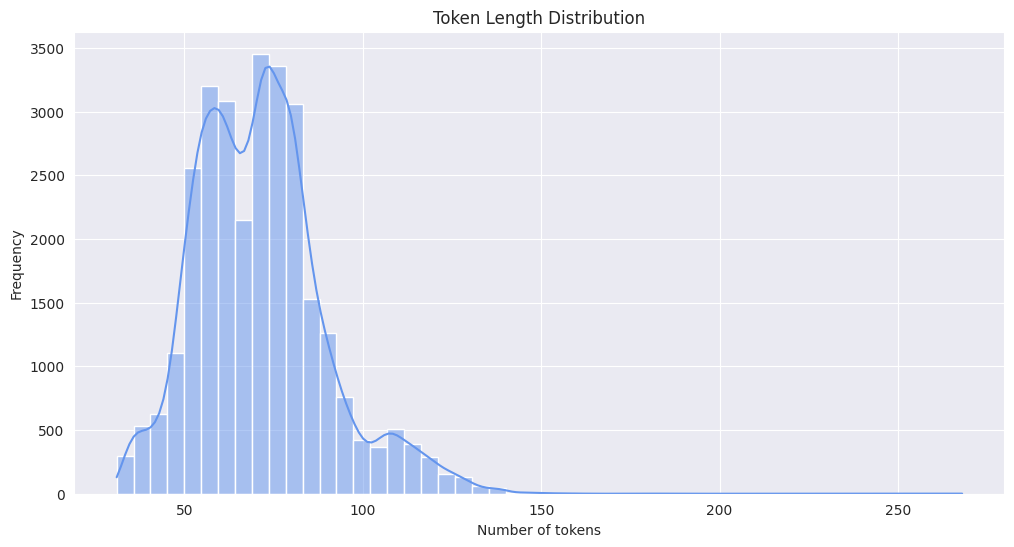

There are 1 train sample(s) with more than 256 tokens: [ 31  31  32 ... 182 231 268]


In [17]:
# Tokenization function
MAX_LEN = 256
def tokenize(batch):
    return tokenizer(batch["text"], padding=False, truncation=True, max_length=MAX_LEN)
    # NOTE: padding=False because we'll use DataCollatorWithPadding

# Tokenize whole dataset
dataset_encoded = hf_dataset.map(tokenize, batched=True)  

print(f"========== Dataset before tokenization: ==========\n {hf_dataset}\n")
print(f"========== Dataset after tokenization: ==========\n {dataset_encoded}\n")

# Check inputs' length (before truncation)
lengths = [len(tokenizer.encode(t, truncation=False)) for t in hf_dataset['train']["text"]]
L = (np.array(lengths)>MAX_LEN).sum()

plt.figure(figsize=(12,6))
sns.histplot(lengths, bins=50, color=CFG.COLOR_1, kde=True)
plt.title("Token Length Distribution")
plt.xlabel("Number of tokens")
plt.ylabel("Frequency")
plt.show()

print(f"There are {L} train sample(s) with more than {MAX_LEN} tokens: {np.sort( lengths )}")

---
## $$WeightedTrainer \ (Trainer \ subclass)$$

> _Why use a weighted trainer?_

This competition’s dataset shows a **strong class imbalance**:  
a few misunderstanding types appear frequently, while others occur only once or twice.

Training without class weights would bias the model toward predicting the most common labels,  
leading to poor recall on rare but important categories.

To address this, we use a **WeightedTrainer**, a modified Hugging Face Trainer that applies  
a class-weighted loss so that underrepresented classes contribute more  
to the gradient updates.

> _Why not use raw weights directly?_

The original class weights span an extreme range (from less than `0.05` up to more than `450`).  
This means that, for the rarest classes, their contribution to the loss would be hundreds of times stronger  
than for common classes. While this seems fair in principle, it often backfires in practice:

- The model may **overfit** to the 1–2 examples of those classes.  
- The gradients can **explode**, causing unstable training or NaNs.  
- The validation loss becomes erratic, and MAP@3 may not improve consistently.

In short, using raw weights directly would make the model “chase” those few examples instead of learning a balanced decision boundary.

> _Why apply weight smoothing (instead of hard capping)?_

We apply a **log-based smoothing transformation** to the normalized weights:

$$
w' = \log(1 + \frac{w}{\bar{w}}) + 1 \\\\\\\\\\\\\\ 
$$[1]

This transformation compresses large weights but preserves their relative importance.  
In contrast, hard capping would simply truncate all extreme values above a fixed threshold,  
potentially erasing meaningful distinctions between moderately rare and ultra-rare classes.

By smoothing instead of capping:
- Training remains numerically stable.  
- Rare classes are still emphasized, just **not overemphasized**.  
- The optimization process becomes more consistent and less noisy.

Thus, **weight smoothing** offers a principled middle ground between ignoring imbalance and  
overcompensating for it.

---

| Aspect | Without Weights | With Raw Weights | With Smoothed Weights |
|---------|----------------|------------------|-----------------------|
| Stability | ✅ Stable | ❌ Unstable (gradient spikes) | ✅ Stable |
| Rare class recall | ❌ Poor | ✅ Very high (but noisy) | ✅ Good and consistent |
| Generalization | ✅ OK | ❌ Overfits rare cases | ✅ Balanced |

[1] _+ 1.0 prevents extremely small weights (< 1) after compression, ensuring the majority class still contributes normally._

---

In [18]:
from torch import nn
from transformers import Trainer
from sklearn.utils.class_weight import compute_class_weight

# Calculate class weights
labels = hf_dataset['train']['label']
class_weights = compute_class_weight(
    class_weight='balanced', 
    classes=np.unique(labels), 
    y=labels
)

# Convert to tensor and normalize to mean = 1
class_weights = torch.tensor(class_weights, dtype=torch.float)
normalized_weights = class_weights / class_weights.mean()

# Smooth: log1p compresses extremes, +1.0 keeps min > 1 to avoid too-small weights
smoothed_weights = torch.log1p(normalized_weights) + 1.0
smoothed_weights = smoothed_weights.to(CFG.DEVICE)

# Subclass Trainer with weighted loss
class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.get("labels")
        outputs = model(**inputs)
        logits = outputs.get("logits")

        # Apply class-weighted CrossEntropy
        loss_fct = nn.CrossEntropyLoss(weight=smoothed_weights)
        loss = loss_fct(logits, labels)
        
        return (loss, outputs) if return_outputs else loss

Unsmoothed class weights range: 0.04 → 451.65
Smoothed class weights range: 1.00 → 2.94


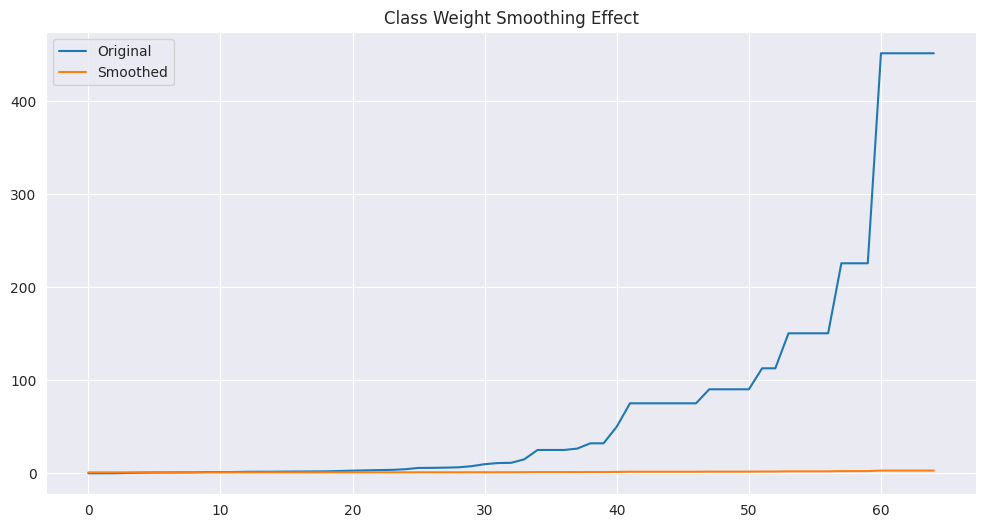

In [19]:
# Weights check (before vs after smoothing)
print(f"Unsmoothed class weights range: {class_weights.min().item():.2f} → {class_weights.max().item():.2f}")
print(f"Smoothed class weights range: {smoothed_weights.min().item():.2f} → {smoothed_weights.max().item():.2f}")

plt.figure(figsize=(12,6))
plt.plot(sorted(class_weights.cpu()), label='Original')
plt.plot(sorted(smoothed_weights.cpu()), label='Smoothed')
plt.legend(); plt.title("Class Weight Smoothing Effect"); plt.show()

---
## $$Progressive \ unfreezing \ strategy$$
In this notebook, we adopt a **progressive unfreezing strategy** for fine-tuning `DeBERTa-v3-large`.

> _Why Progressive Unfreezing?_

Transformer-based models like DeBERTa have **many layers** that encode linguistic and semantic information at different levels of abstraction.  
If we unfreeze all layers at once on a small or specialized dataset, the pretrained weights may drift too quickly, leading to **catastrophic forgetting** or **unstable training**.

Progressive unfreezing offers a controlled way to adapt:

1. **Stage 1 — Shallow Adaptation**  
   Only the **classifier head** and the **top 4 encoder layers** are trainable.  
   These layers capture high-level task representations and adapt quickly to the new task.

2. **Stage 2 — Deeper Adaptation**  
   Once the top layers stabilize, we unfreeze more: the **last 8 encoder layers**.  
   This allows the model to refine deeper contextual representations, improving generalization without disrupting the pretrained knowledge base.

## $$Differential \ learning \ rates$$
We also make use of **differential learning rates**:
- A higher learning rate for the **classifier head** (to learn quickly from scratch).  
- A smaller rate for the **unfrozen encoder layers** (to preserve pretrained knowledge).

This combination provides the best of both worlds:
- Rapid adaptation to the new domain.
- Stable convergence with minimal overfitting.
---

In [20]:
import os
from transformers import TrainingArguments

# Directory full path
DIR = os.path.join(CFG.BASE_DIRECTORY, CFG.CHALLENGE_NAME, CFG.MODEL_NAME)

# DIR = make_model_dir(
#     base_dir=       CFG.BASE_DIRECTORY,
#     challenge_name= CFG.CHALLENGE_NAME,
#     model_name=     CFG.MODEL_NAME,
#     stage_name=""
# )

# Stages configs
stages = {
    "stage_1": {
        "freeze_strategy"  : lambda model: unfreeze_last_n_layers(model, n_unfrozen=4),
        "optimizer"        : lambda model: get_optimizer(model, lr_head=5e-5, lr_base=1e-5, n_unfrozen=4, custom=True),
        "train_args"       : TrainingArguments(
            output_dir=f'.{DIR}_stage1',
            learning_rate=2e-5,                       # overridden by custom optimizer
            num_train_epochs=CFG.EPOCHS,
            warmup_ratio=0.1, 
            per_device_train_batch_size=16*2,
            per_device_eval_batch_size=31*2,
            # gradient_accumulation_steps=4,
            weight_decay=0.01,
            max_grad_norm=1.0,
            seed=CFG.SEED,
            metric_for_best_model="map@3",
            load_best_model_at_end=False,
            greater_is_better=True,
            eval_strategy="epoch",
            save_strategy="no",                      # skip periodic checkpoint saving
            # save_total_limit=3,
            logging_steps=10,
            report_to="none",
        )
    },
    
    "stage_2": {
        "freeze_strategy"  : lambda model: unfreeze_last_n_layers(model, n_unfrozen=8),
        "optimizer"        : lambda model: get_optimizer(model, lr_head=3e-5, lr_base=8e-6, n_unfrozen=8, custom=True),
        "train_args"       : TrainingArguments(
            output_dir=f'.{DIR}_stage2',
            learning_rate=2e-5,                     # should be overridden by custom optimizer
            num_train_epochs=CFG.EPOCHS,
            warmup_ratio=0.1,    
            per_device_train_batch_size=8,          # instead of 32
            per_device_eval_batch_size=8,
            gradient_accumulation_steps=4,          # keeps effective batch 32
            fp16=True,                              # mixed precision
            gradient_checkpointing=False,           # True: recompute activations to save memory
            weight_decay=0.01,
            max_grad_norm=1.0,
            seed=CFG.SEED,
            metric_for_best_model="map@3",
            load_best_model_at_end=True,
            greater_is_better=True,
            eval_strategy="epoch",
            save_strategy="epoch",
            save_total_limit=3,
            logging_steps=10,
            report_to="none",
        )
    },
}

**NOTE: potential OOM errors**

In **stage 2** we went from unfreezing the last 4 layers to unfreezing the last 8.

That means:
* Gradients are now computed and stored for roughly **twice as many parameters**.
* DeBERTa-large uses 24 layers; doubling the number of trainable layers roughly doubles memory footprint for activations + gradients.

So even though batch size, sequence length, and optimizer stayed constant, the effective GPU load increased.

| Fix                            | What it does                                        | Cost                               |
| ------------------------------ | --------------------------------------------------- | ---------------------------------- |
| **Reduce batch size**          | Directly lowers memory footprint                    | Slower per epoch                   |
| **Use gradient accumulation**  | Keeps effective batch size while splitting GPU load | Slight overhead                    |
| **Use `fp16` mixed precision** | Cuts memory roughly in half                         | Slight precision loss (negligible) |
| **Gradient checkpointing**     | Saves activations recomputed on backward pass       | +30–40 % training time             |

In [21]:
import time

if CFG.TRAINING:
    for name, cfg in stages.items():
        print(f"\n===== Running {name.upper()} =====\n")

        # Apply freezing strategy
        cfg["freeze_strategy"](model)
        count_trainable_params(model)

        # Define optimizer
        optimizer = cfg["optimizer"](model)
        
        # Initialize trainer
        trainer = WeightedTrainer(
        model=model,
        tokenizer=tokenizer,
        data_collator=data_collator,
        args=cfg["train_args"],
        train_dataset=dataset_encoded["train"],
        eval_dataset=dataset_encoded["valid"],
        compute_metrics=compute_map3,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=CFG.PATIENCE)],
        optimizers=(optimizer, None) if optimizer is not None else (None, None)
        )

        # Start training
        start = time.time()
        
        if name == 'stage_2':
            # trainer.train(resume_from_checkpoint=f"{DIR}_stage1")
            trainer.train()
        else:
            trainer.train()
            trainer.save_model(f"{DIR}_stage1")
        end = time.time()
        print(f"Training time {name}: {(end - start)/60:.2f} min")

# $$Save \ model$$

In [22]:
if CFG.TRAINING:
    model.save_pretrained(f'.{DIR}')      
    tokenizer.save_pretrained(f'.{DIR}')

# $$Load \ model and  \ predict \ test$$ 

In [23]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
if CFG.PRE_TRAINED:
    model = AutoModelForSequenceClassification.from_pretrained(CFG.PRETRAINED_CHECKPOINT,
                                                              config=config)
    tokenizer = AutoTokenizer.from_pretrained(CFG.PRETRAINED_CHECKPOINT)
    training_args = TrainingArguments(report_to="none")
    trainer   = WeightedTrainer(model=model, tokenizer=tokenizer, data_collator=data_collator, args=training_args)

/tmp/ipykernel_19/4039942641.py:7: FutureWarning:

`tokenizer` is deprecated and will be removed in version 5.0.0 for `WeightedTrainer.__init__`. Use `processing_class` instead.



In [24]:
from transformers import pipeline
from tqdm.auto import tqdm

pipe = pipeline(task='text-classification', model=model, tokenizer=tokenizer, device=CFG.DEVICE)
pipe.predict(['This is a test'])

Device set to use cuda


[{'label': 'True_Neither:NA', 'score': 0.8082223534584045}]

In [25]:
ds_test = Dataset.from_pandas(TEST_DF[['text']])
ds_test = ds_test.map(tokenize, batched=True)

predictions = trainer.predict(ds_test)
probs = torch.nn.functional.softmax(torch.tensor(predictions.predictions), dim=1).numpy()

Map:   0%|          | 0/3 [00:00<?, ? examples/s]

# $$Submission \ CSV$$

In [26]:
# Get top 3 predicted class indices
top3 = np.argsort(-probs, axis=1)[:, :3]   # shape: [num_samples, 3]

# Decode numeric class indices to original string labels 
flat_top3 = top3.flatten()
decoded_labels = le.inverse_transform(flat_top3)
top3_labels = decoded_labels.reshape(top3.shape)

# Join 3 labels per row with space
joined_preds = [" ".join(row) for row in top3_labels]

# Save submission
sub = pd.DataFrame({
    "row_id": TEST_DF.row_id.values,
    "Category:Misconception": joined_preds
})
sub.to_csv("submission.csv", index=False)
sub.head()

,row_id,Category:Misconception
0,36696,True_Correct:NA True_Neither:NA True_Misconcep...
1,36697,False_Misconception:WNB False_Neither:NA False...
2,36698,True_Neither:NA True_Correct:NA True_Misconcep...


#### $$Acknowledgment$$ 
This notebook builds upon the [*DeBERTa Starter* notebook](https://www.kaggle.com/code/cdeotte/deberta-starter-cv-0-930) by **Chris Deotte**, adapting it with a curriculum-style fine-tuning approach that integrates progressive unfreezing, dual learning rates, and class-balanced optimization. 
